# 03 — Load and PV profiles

**Concept:** a profile is a dimensionless **shape** from a source (Enedis, a CSV file, a synthetic generator) times a **scaling** that gives one constant factor in kW, so the same profile serves any period and any step.

**You will learn:** how Enedis shapes are read across their 30 → 15-minute switch, how `Nominal`, `Calibrated` and `PVSystem` turn shapes into kW, how synthetic and measured profiles fit in, and why a scaling that does not fit a profile is refused.

In [1]:
from datetime import datetime, timedelta
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt

from myenergy.adapters.profiles.csv_files import CsvProfile, CsvProfileSource, CsvUnit
from myenergy.adapters.profiles.enedis import EnedisParquetSource
from myenergy.adapters.profiles.synthetic import SyntheticProfileSource
from myenergy.domain.errors import CalibrationError
from myenergy.domain.profiles import (
    AsMeasured,
    Calibrated,
    Nominal,
    ProfileKind,
    ProfileRef,
    PVSystem,
    Shaped,
)
from myenergy.domain.time import TimeGrid
from myenergy.engine.profiles import ProfileResolver

PARIS = ZoneInfo("Europe/Paris")
FIXTURES = Path("../tests/fixtures")  # two weeks of real Enedis data, Licence Ouverte 2.0
enedis = EnedisParquetSource(FIXTURES / "enedis")
for meta in enedis.catalog():
    span = f"{meta.coverage.start:%Y-%m-%d} → {meta.coverage.end:%Y-%m-%d}"
    print(f"{meta.key:10} {meta.kind:12} {span}")

PRD3_BASE  production   2024-09-28 → 2024-10-12
RES1_BASE  consumption  2024-09-28 → 2024-10-12


## Enedis shapes, across the resolution switch

Until 2024-10-04 22:00 UTC Enedis published one coefficient per 30 minutes, then one per 15 minutes. The source holds each value over its own interval, on the finest step, so any grid can be requested. The coefficients average about 1 over a year: they are shapes, not kW.

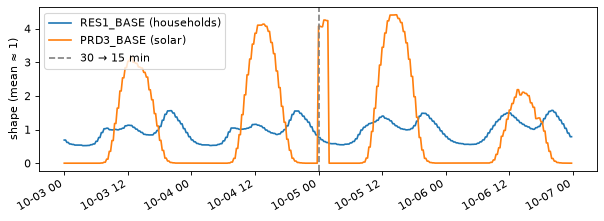

In [2]:
quarter = timedelta(minutes=15)
days = TimeGrid(
    start=datetime(2024, 10, 3, tzinfo=PARIS), end=datetime(2024, 10, 7, tzinfo=PARIS), step=quarter
)
res1 = enedis.shape("RES1_BASE", days)
prd3 = enedis.shape("PRD3_BASE", days)
times = [days.local(i) for i in range(len(days))]
fig, ax = plt.subplots(figsize=(9, 3), dpi=80)
ax.plot(times, res1.values, label="RES1_BASE (households)")
ax.plot(times, prd3.values, label="PRD3_BASE (solar)")
ax.axvline(datetime(2024, 10, 5, tzinfo=PARIS), color="grey", linestyle="--", label="30 → 15 min")
ax.set_ylabel("shape (mean ≈ 1)")
ax.legend(loc="upper left")
fig.autofmt_xdate()

**A data anomaly, shown as it is.** The solar shape jumps to about 4 at midnight on 5 October (22:00–00:00 UTC on the 4th), exactly at the resolution switch. Those values match the same day's midday values, which points to a 12-hour shift. They are in Enedis's own published data (checked against the Enedis API), not introduced by our download. The reader does not hide or repair them: nothing passes silently. A data curator that flags such problems is on the roadmap.

## Nominal: an annual energy

`Nominal(annual_kwh)` gives kW = shape × annual energy / 8760 h. A household using 3 500 kWh a year draws about 0.4 kW on average; over these four October days it uses:

In [3]:
resolver = ProfileResolver({"enedis": enedis})
home = ProfileRef(source="enedis", key="RES1_BASE")
load = resolver.power(Shaped(ref=home, scaling=Nominal(annual_kwh=3500)), days)
f"{load.energy().total():.1f} kWh, mean {load.time_mean():.2f} kW, peak {load.values.max():.2f} kW"

'37.5 kWh, mean 0.39 kW, peak 0.63 kW'

## Calibrated: a known energy over any window

If a bill says 45 kWh were used from 3 to 7 October, `Calibrated` makes the profile match exactly over that window, whatever the step. The window can be any period: a billing year starting in November, a month, a week.

In [4]:
window = days
calibrated = Shaped(ref=home, scaling=Calibrated(energy_kwh=45.0, window=window))
for minutes in (5, 15, 60):
    grid = window.with_step(timedelta(minutes=minutes))
    print(f"{minutes:>2}-minute steps: {resolver.power(calibrated, grid).energy().total():.6f} kWh")

 5-minute steps: 45.000000 kWh
15-minute steps: 45.000000 kWh
60-minute steps: 45.000000 kWh


## PVSystem: peak power × specific yield

Until a PV API (PVGIS, NASA POWER) computes production from the site, a 3 kWp array yielding 1 200 kWh/kWp a year scales the solar shape. Plotted with the household, the midday surplus and the evening deficit appear: that is what dispatch will have to manage.

'PV 41.6 kWh vs load 37.5 kWh over the four days'

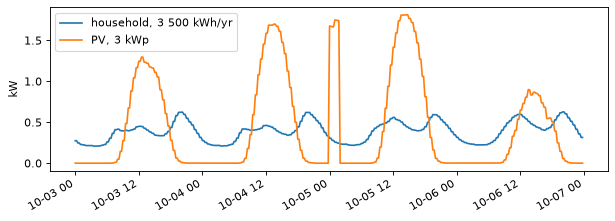

In [5]:
pv = resolver.power(
    Shaped(
        ref=ProfileRef(source="enedis", key="PRD3_BASE"),
        scaling=PVSystem(peak_kwp=3, specific_yield_kwh_per_kwp=1200),
    ),
    days,
)
fig, ax = plt.subplots(figsize=(9, 3), dpi=80)
ax.plot(times, load.values, label="household, 3 500 kWh/yr")
ax.plot(times, pv.values, label="PV, 3 kWp")
ax.set_ylabel("kW")
ax.legend(loc="upper left")
fig.autofmt_xdate()
f"PV {pv.energy().total():.1f} kWh vs load {load.energy().total():.1f} kWh over the four days"

## Synthetic profiles

The synthetic source gives deterministic shapes for any date from 2000 to 2100: a household with seeded noise, a clear-sky PV curve for a location, and a constant. A value never depends on the window it is requested for.

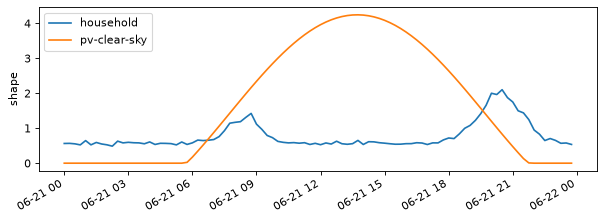

In [6]:
synthetic = SyntheticProfileSource(seed=1)
june = TimeGrid(
    start=datetime(2026, 6, 21, tzinfo=PARIS), end=datetime(2026, 6, 22, tzinfo=PARIS), step=quarter
)
fig, ax = plt.subplots(figsize=(9, 3), dpi=80)
for key in ("household", "pv-clear-sky"):
    ax.plot([june.local(i) for i in range(len(june))], synthetic.shape(key, june).values, label=key)
ax.set_ylabel("shape")
ax.legend(loc="upper left")
fig.autofmt_xdate()

## Measured profiles, and refusals

A meter export in kW (or kWh per step) is already power: its CSV source marks it `kW`, and `AsMeasured()` uses it as is. Scaling it as if it were a shape would be wrong, so the resolver refuses the pairing instead of guessing.

In [7]:
meter = CsvProfileSource(
    [
        CsvProfile(
            key="home",
            path=FIXTURES / "csv" / "home-kw.csv",
            kind=ProfileKind.CONSUMPTION,
            unit=CsvUnit.KW,
        )
    ]
)
measured = ProfileResolver({"csv": meter})
ref = ProfileRef(source="csv", key="home")
grid = meter.catalog()[0].coverage
energy = measured.power(Shaped(ref=ref, scaling=AsMeasured()), grid).energy().total()
print(f"{energy:.2f} kWh measured")
try:
    measured.power(Shaped(ref=ref, scaling=Nominal(annual_kwh=3500)), grid)
except CalibrationError as error:
    print(error)

25.50 kWh measured
Nominal needs a profile in '1', but csv/home is in 'kW'


**Next:** 04 — Anatomy of a bill (M2) prices every kWh of these profiles, with the network charge, taxes and VAT that apply to each energy flow.